# Task 0: Power as a polynomial of speed and flow (Case 1)

**Owner:** Seb

Use Linear Regression to predict the power **P** from n (in krpm) and Q:

$$P = \sum_{i=0}^{3}\sum_{j=0}^{3} \alpha_{ij}\, n^i Q^j$$

Apply a **feature selection** method to find which terms belong in the formula. Train on train1, test on test1, report the final expression and the test errors, and plot the errors vs flow.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import cross_val_score, KFold, GridSearchCV
import sympy as sp
from sklearn.preprocessing import StandardScaler

import sys
sys.path.append("..")
from src.data import load_case1

In [2]:
#Data naming and cleaning. 
df_train, df_test  =load_case1()
n_train, n_test = df_train["speed_rpm"] / 1000, df_test["speed_rpm"] / 1000   #now in kilo-rotations/minute!
Q_train, Q_test = np.array(df_train["flow_m3_h"]), np.array(df_test["flow_m3_h"])
y_train, y_test = np.array(df_train["power_w"]), np.array(df_test["power_w"]) #target variable

In [3]:
#From the given polynomial equation, design matrix X will have 16 featuers (cycling through both sum signs)

n , Q = sp.symbols("n, Q")

design_matrix = []

for i in range(4):
    for j in range(4):
        design_matrix.append(n**i * Q**j)

print("Design matrix in symbolic notation: \n", design_matrix)

#Now we create a design matrix with actual data

X_trainlist, X_testlist = [], []
index = 0

for i in range(4):
    for j in range(4):
        X_trainlist.append(n_train**i * Q_train**j)
        X_testlist.append(n_test**i * Q_test**j)

X_train = np.array(X_trainlist).T
X_test = np.array(X_testlist).T


Design matrix in symbolic notation: 
 [1, Q, Q**2, Q**3, n, Q*n, Q**2*n, Q**3*n, n**2, Q*n**2, Q**2*n**2, Q**3*n**2, n**3, Q*n**3, Q**2*n**3, Q**3*n**3]


Backward feature selection

------------------------------ Backward selection results: ------------------------------
 Number of Features  mean_cv_rmse  std_cv_rmse
                  1    178.688061    15.562152
                  2    119.007378     5.192588
                  3     90.196319     7.047062
                  4     38.758620     4.357479
                  5     18.236549     1.133495
                  6     16.011866     1.165254
                  7     12.930903     1.612346
                  8     10.762426     1.047665
                  9     10.480885     1.108237
                 10     10.503768     1.070208
                 11     10.521799     1.079241
                 12     10.443591     1.107750
                 13     10.443591     1.107750
                 14     10.476923     1.077821
                 15     10.493115     1.059676


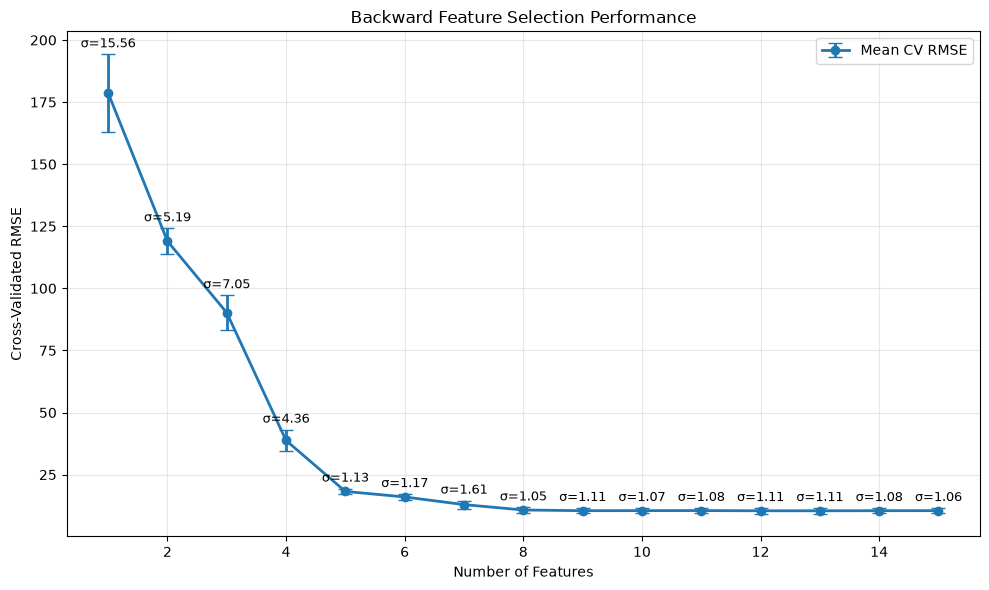

In [4]:
#Testing performance of different models from backward selection


#SequentialFeatureSelector only allows features_to_select to be less than n_features. So we make a model with all features after this loop.
no_fts = np.arange(1,16) 
model = LinearRegression()
results = []
cross_validation = KFold(n_splits=5, shuffle=True, random_state=42)
for i in no_fts:
    sfs = SequentialFeatureSelector(model, direction = "backward", cv = 5, n_features_to_select= i)
    sfs.fit(X_train, y_train)
    selected_X_train = sfs.transform(X_train) #only relevent features selected

    #getting cross validation score

    fold_rmse = -cross_val_score(
        model, selected_X_train, y_train, 
        cv = cross_validation, 
        scoring="neg_root_mean_squared_error"
        )

    results.append({"Number of Features": i, "mean_cv_rmse": fold_rmse.mean(), "std_cv_rmse": fold_rmse.std()})

cv_results = pd.DataFrame(results)

print("-"*30, "Backward selection results:", "-"*30)
print(cv_results.to_string(index=False))

#plotting: 
plt.figure(figsize=(10, 6))

plt.errorbar(
    cv_results["Number of Features"],
    cv_results["mean_cv_rmse"],
    yerr=cv_results["std_cv_rmse"],
    fmt="o-",
    capsize=5,
    linewidth=2,
    label="Mean CV RMSE"
)

# Add std values above each error bar
for x, mean, std in zip(
    cv_results["Number of Features"],
    cv_results["mean_cv_rmse"],
    cv_results["std_cv_rmse"]
):
    plt.annotate(
        f"σ={std:.2f}",
        (x, mean + std),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

plt.xlabel("Number of Features")
plt.ylabel("Cross-Validated RMSE")
plt.title("Backward Feature Selection Performance")
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


In [5]:
#Identifying the best number of features (lowest mean RMSE):

print("-"*30, "Backward selection results:", "-"*30)

best_num_features = int(cv_results.loc[cv_results["mean_cv_rmse"].idxmin(), "Number of Features"])
print("Chosen number of features:", best_num_features, "\n")

sfs = SequentialFeatureSelector(model, direction = "backward", cv = 5, n_features_to_select= best_num_features)
sfs.fit(X_train, y_train)

X_train_selected = sfs.transform(X_train)
X_test_selected = sfs.transform(X_test)
best_model = LinearRegression().fit(X_train_selected, y_train)

print("Selected features: ")
for i in np.argwhere(sfs.get_support() ==True).flatten():
    print (design_matrix[i])
print("\n")
print("Coefficients: ", best_model.coef_)

y_pred = best_model.predict(X_test_selected)
print("train RMSE score for selected model: ", root_mean_squared_error(y_train, best_model.predict(X_train_selected)))
print("test RMSE for selected model: ", root_mean_squared_error(y_test, best_model.predict(X_test_selected)))
print("R-Squared value: ", r2_score(y_test, best_model.predict(X_test_selected)))

------------------------------ Backward selection results: ------------------------------
Chosen number of features: 13 

Selected features: 
1
Q
Q**2
Q**3
Q*n
Q**2*n
Q**3*n
Q**2*n**2
Q**3*n**2
n**3
Q*n**3
Q**2*n**3
Q**3*n**3


Coefficients:  [ 0.00000000e+00 -9.12777047e+00  8.87918767e-01 -3.23044783e-02
  8.29123924e+00 -8.29668599e-01  2.07161803e-02  2.17817908e-01
 -5.71170526e-03  7.64494911e+00  2.25142351e-01 -1.95534330e-02
  5.07149667e-04]
train RMSE score for selected model:  10.219242438532412
test RMSE for selected model:  10.391195767195592
R-Squared value:  0.9996269589459299


Forward feature selection

------------------------------ Forward selection results: ------------------------------
 Number of Features  mean_cv_rmse  std_cv_rmse
                  1    178.688061    15.562152
                  2    115.882288     6.149983
                  3     11.478028     0.882960
                  4     10.398158     0.978477
                  5     10.398158     0.978477
                  6     10.419012     0.985242
                  7     10.484815     1.006065
                  8     10.488942     1.032753
                  9     10.477364     1.035779
                 10     10.493400     1.023234
                 11     10.498668     1.033519
                 12     10.513078     1.038963
                 13     10.495658     1.067992
                 14     10.529453     1.057640
                 15     10.617626     1.070651


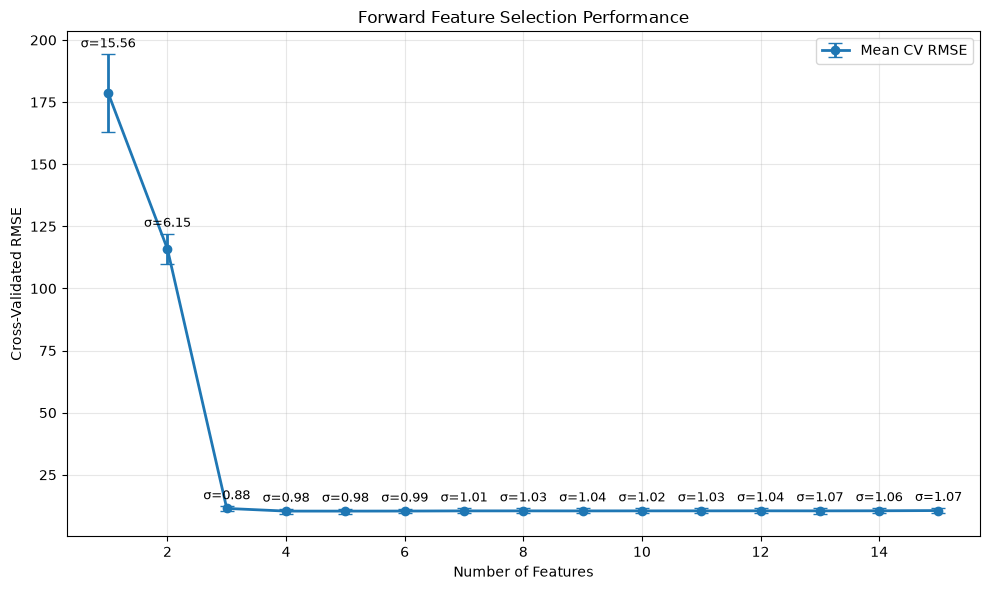

In [6]:
#Testing performance of different models from forward selection


#SequentialFeatureSelector only allows features_to_select to be less than n_features. So we make a model with all features after this loop.
no_fts = np.arange(1,16) 
model = LinearRegression()
results = []
cross_validation = KFold(n_splits=5, shuffle=True, random_state=42)
for i in no_fts:
    sfs = SequentialFeatureSelector(model, direction = "forward", cv = 5, n_features_to_select= i)
    sfs.fit(X_train, y_train)
    selected_X_train = sfs.transform(X_train) #only relevent features selected

    #getting cross validation score

    fold_rmse = -cross_val_score(
        model, selected_X_train, y_train, 
        cv = cross_validation, 
        scoring="neg_root_mean_squared_error"
        )

    results.append({"Number of Features": i, "mean_cv_rmse": fold_rmse.mean(), "std_cv_rmse": fold_rmse.std()})

cv_results = pd.DataFrame(results)

print("-"*30, "Forward selection results:", "-"*30)
print(cv_results.to_string(index=False))

#plotting: 
plt.figure(figsize=(10, 6))

plt.errorbar(
    cv_results["Number of Features"],
    cv_results["mean_cv_rmse"],
    yerr=cv_results["std_cv_rmse"],
    fmt="o-",
    capsize=5,
    linewidth=2,
    label="Mean CV RMSE"
)

# Add std values above each error bar
for x, mean, std in zip(
    cv_results["Number of Features"],
    cv_results["mean_cv_rmse"],
    cv_results["std_cv_rmse"]
):
    plt.annotate(
        f"σ={std:.2f}",
        (x, mean + std),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

plt.xlabel("Number of Features")
plt.ylabel("Cross-Validated RMSE")
plt.title("Forward Feature Selection Performance")
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


In [7]:
#Identifying the best number of features (lowest mean RMSE):

print("-"*30, "Forward selection results:", "-"*30)

best_num_features = int(cv_results.loc[cv_results["mean_cv_rmse"].idxmin(), "Number of Features"])
print("Chosen number of features:", best_num_features, "\n")

sfs = SequentialFeatureSelector(model, direction = "forward", cv = 5, n_features_to_select= best_num_features)
sfs.fit(X_train, y_train)

X_train_selected = sfs.transform(X_train)
X_test_selected = sfs.transform(X_test)
best_model = LinearRegression().fit(X_train_selected, y_train)

print("Selected features: ")
for i in np.argwhere(sfs.get_support() ==True).flatten():
    print (design_matrix[i])
print("\n")
print("Coefficients: ", best_model.coef_)

y_pred = best_model.predict(X_test_selected)
print("train RMSE score for selected model: ", root_mean_squared_error(y_train, best_model.predict(X_train_selected)))
print("test RMSE for selected model: ", root_mean_squared_error(y_test, best_model.predict(X_test_selected)))
print("R-Squared value: ", r2_score(y_test, best_model.predict(X_test_selected)))

------------------------------ Forward selection results: ------------------------------
Chosen number of features: 4 

Selected features: 
Q**3
Q**2*n
Q*n**2
n**3


Coefficients:  [-0.0083797  -0.04956388  2.40724691  7.65781782]
train RMSE score for selected model:  10.338480707745275
test RMSE for selected model:  10.358675167956145
R-Squared value:  0.9996292902531841


Lasso regression

In [8]:
lasso = Lasso()
lasso.fit(X_train, y_train)

c:\Users\Sebastian Nguyen\miniconda3\envs\ml\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.374e+04, tolerance: 1.467e+04
  model = cd_fast.enet_coordinate_descent(


,alpha,1.0
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [9]:
#tuning hyperparameter alpha
param_grid = {
    "alpha" : [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

lasso_cv = GridSearchCV(lasso, param_grid, scoring = "neg_root_mean_squared_error",cv = 5, n_jobs = -1)
lasso_cv.fit(X_train, y_train)
lasso_cv.best_estimator_

c:\Users\Sebastian Nguyen\miniconda3\envs\ml\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.463e+04, tolerance: 1.467e+04
  model = cd_fast.enet_coordinate_descent(


,alpha,10
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [10]:
lasso2 = Lasso(alpha = 10) 
lasso2.fit(X_train, y_train)

c:\Users\Sebastian Nguyen\miniconda3\envs\ml\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.463e+04, tolerance: 1.467e+04
  model = cd_fast.enet_coordinate_descent(


,alpha,10
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [11]:
print("-"*30, "Lasso regression results(alpha = 10)):", "-"*30)
mask = lasso2.coef_ != 0
sym_array = np.array(design_matrix)
lasso_features = sym_array[mask]
print("Number of features selected:", len(lasso_features))
print("Selected freatures: ")
for i in lasso_features:
    print(i)
print("\n")
print("Coeffients: ")
print(lasso2.coef_[mask])
print("\n")
y_pred = lasso2.predict(X_test)
print("train RMSE score for selected model: ", root_mean_squared_error(y_train, lasso2.predict(X_train)))
print("test RMSE for selected model: ", root_mean_squared_error(y_test, y_pred))
print("R-Squared value: ", r2_score(y_test, y_pred))

------------------------------ Lasso regression results(alpha = 10)): ------------------------------
Number of features selected: 12
Selected freatures: 
Q**2
Q**3
Q*n
Q**2*n
Q**3*n
Q*n**2
Q**2*n**2
Q**3*n**2
n**3
Q*n**3
Q**2*n**3
Q**3*n**3


Coeffients: 
[-2.42925743e-01 -6.68098274e-03  2.76143536e+00  3.40221421e-02
 -4.31944831e-04  1.12162344e+00 -7.52590615e-04 -3.05472133e-05
  7.76531259e+00  1.32813278e-01 -5.28705641e-04  1.59945850e-07]


train RMSE score for selected model:  10.570919109911467
test RMSE for selected model:  10.2566575907015
R-Squared value:  0.9996365561785182


Lasso regression is chosen. Now plotting flow vs error

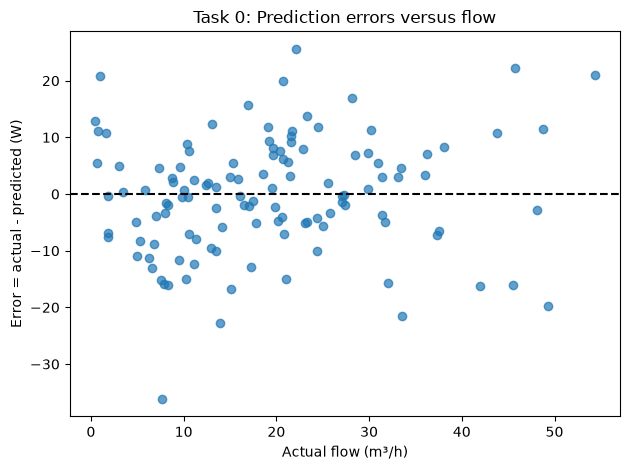

In [29]:
errors = []
for i in range(len(y_test)):
    pred = lasso2.predict(X_test[i].reshape(1,-1))[0]
    errors.append(y_test[i]-pred)

plt.scatter(Q_test, errors, alpha = 0.7)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Actual flow (m³/h)")
plt.ylabel("Error = actual - predicted (W)")
plt.title("Task 0: Prediction errors versus flow")
plt.tight_layout()
plt.show()